# 08 · Feature engineering

## Purpose

Apply small, deterministic feature interactions that can be recomputed identically during model inference.

## Method

Add only price-discount, price-rating, and session views-per-minute interactions when their source columns exist. Inspect the transformed schema and missing values; do not construct future-derived customer aggregates.

## Interpretation

Use the displayed tables, figures, and saved metrics produced by this run. Do not fill this section with assumed outcomes. For every result, distinguish observed evidence from interpretation.

## Limitations

The feature interactions are candidate representations, not known causal mechanisms. Compare them through cross-validated ablations before retaining them.

## References

Feature engineering is implemented in returnwise.features.ReturnWiseFeatureEngineer.


In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
while not (ROOT / 'returnwise').is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from IPython.display import display
from returnwise.research_state import load_state, save_state
state = load_state()
print('Project:', ROOT)
print('Notebook:', '08 · Feature engineering')


Project: C:\Users\Lenovo\Documents\Who is back
Notebook: 08 · Feature engineering


Input shape: (160000, 11) | engineered shape: (160000, 14)
Interactions added when source fields were available: ['price_discount_interaction', 'views_per_session_minute', 'price_rating_interaction']


,count,mean,std,min,25%,50%,75%,max
price_discount_interaction,160000.0,1582.214715,2259.270236,-11939.315689,178.528482,816.929540,2126.510728,53190.520818
views_per_session_minute,160000.0,0.320385,20.987072,-1985.970151,0.040506,0.168604,0.338947,7077.648614
price_rating_interaction,160000.0,107.010619,147.632474,-744.480276,14.953227,57.999045,142.865820,3391.275134


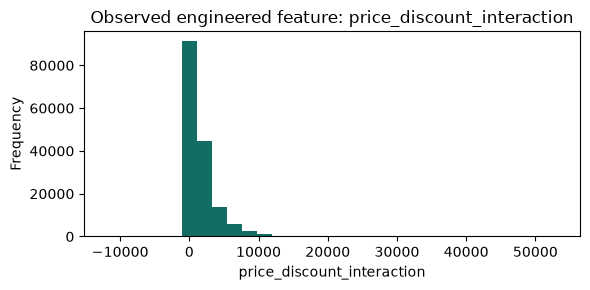

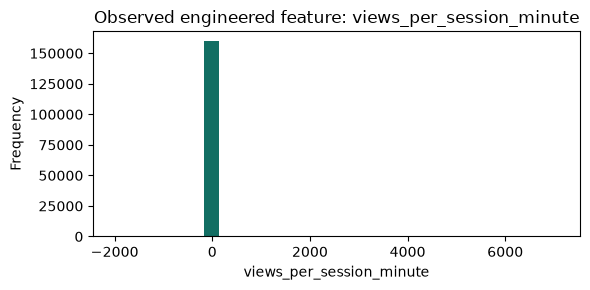

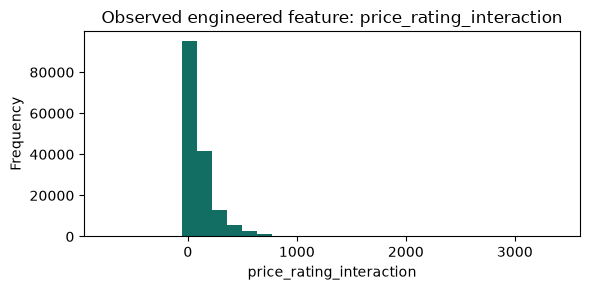

In [2]:
from returnwise.features import ReturnWiseFeatureEngineer
from returnwise.research_state import load_state, save_state
import matplotlib.pyplot as plt

state = load_state()
if 'X_train' not in state:
    raise RuntimeError('Run notebook 07 first to create the training split.')
X_train = state['X_train']
engineered = ReturnWiseFeatureEngineer().fit_transform(X_train)
new_features = [c for c in engineered.columns if c not in X_train.columns]
print('Input shape:', X_train.shape, '| engineered shape:', engineered.shape)
print('Interactions added when source fields were available:', new_features)
display(engineered[new_features].describe().T if new_features else engineered.describe(include='all').T.head(20))
for feature in new_features[:4]:
    ax = engineered[feature].dropna().plot.hist(bins=30, figsize=(6, 3), color='#126E63', title=f'Observed engineered feature: {feature}')
    ax.set_xlabel(feature)
    plt.tight_layout()
    plt.show()
state['engineered_feature_columns'] = new_features
save_state(state)
